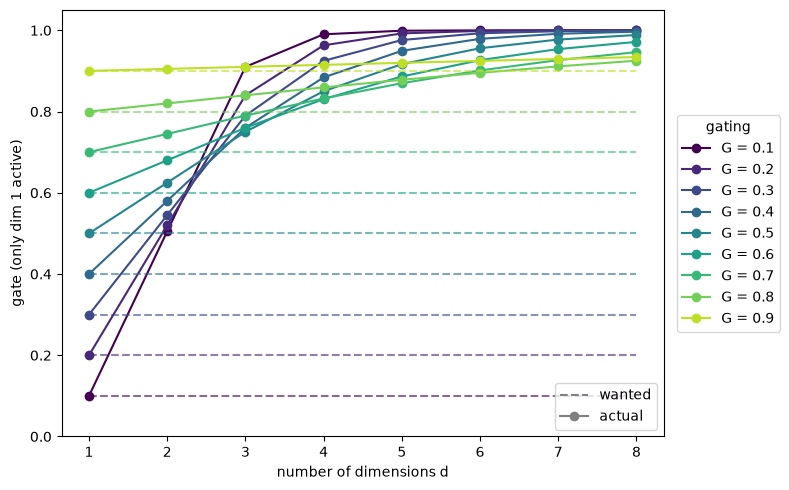

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

d = np.arange(1, 9)
gatings = np.round(np.arange(0.1, 1.0, 0.1), 1)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(gatings)))

fig, ax = plt.subplots(figsize=(8, 5))
for G, c in zip(gatings, colors):
    ax.plot(d, np.full(d.shape, G), '--', color=c, alpha=0.6)
    ax.plot(d, (1 + G**d) / (1 + G**(d - 2.)), 'o-', color=c, label=f'G = {G}')

style_legend = ax.legend(handles=[Line2D([], [], color='gray', ls='--', label='wanted'),
                                                              Line2D([], [], color='gray', ls='-', marker='o', label='actual')],
                                             loc='lower right')
ax.add_artist(style_legend)
ax.legend(title='gating', loc='center left', bbox_to_anchor=(1.01, 0.5))

ax.set_xlabel('number of dimensions d')
ax.set_ylabel('gate (only dim 1 active)')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

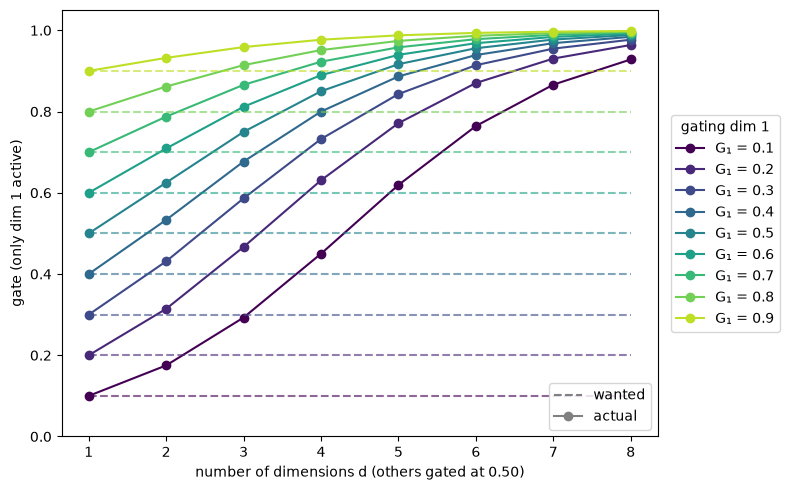

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

d = np.arange(1, 9)
G_o = 0.5
h = G_o ** (d - 1.)
gatings = np.round(np.arange(0.1, 1.0, 0.1), 1)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(gatings)))

fig, ax = plt.subplots(figsize=(8, 5))
for G1, c in zip(gatings, colors):
    ax.plot(d, np.full(d.shape, G1), '--', color=c, alpha=0.6)
    ax.plot(d, (1 + G1 * h) / (1 + h / G1), 'o-', color=c, label=f'G₁ = {G1}')

style_legend = ax.legend(handles=[Line2D([], [], color='gray', ls='--', label='wanted'),
                                                              Line2D([], [], color='gray', ls='-', marker='o', label='actual')],
                                             loc='lower right')
ax.add_artist(style_legend)
ax.legend(title='gating dim 1', loc='center left', bbox_to_anchor=(1.01, 0.5))

ax.set_xlabel(f'number of dimensions d (others gated at {G_o:.2F})')
ax.set_ylabel('gate (only dim 1 active)')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

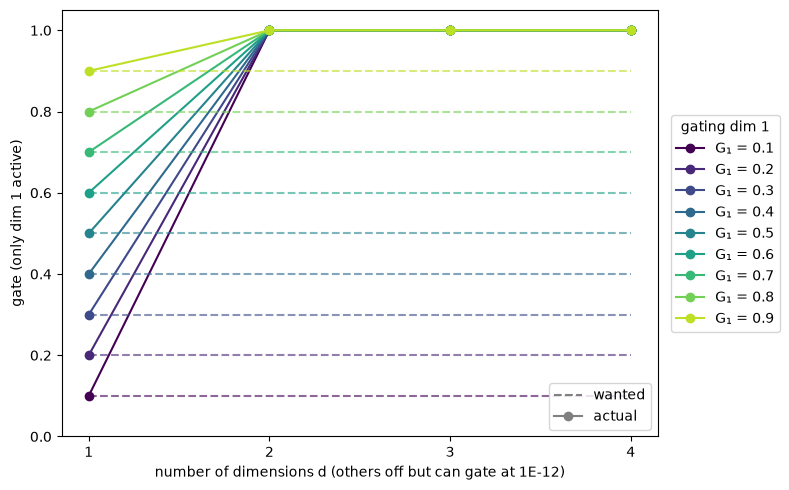

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

d = np.arange(1, 4+1)
G_o = 1e-12
h = G_o ** (d - 1.)
gatings = np.round(np.arange(0.1, 1.0, 0.1), 1)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(gatings)))

fig, ax = plt.subplots(figsize=(8, 5))
for G1, c in zip(gatings, colors):
    ax.plot(d, np.full(d.shape, G1), '--', color=c, alpha=0.6)
    ax.plot(d, (1 + G1 * h) / (1 + h / G1), 'o-', color=c, label=f'G₁ = {G1}')

style_legend = ax.legend(handles=[Line2D([], [], color='gray', ls='--', label='wanted'),
                                                              Line2D([], [], color='gray', ls='-', marker='o', label='actual')],
                                             loc='lower right')
ax.add_artist(style_legend)
ax.legend(title='gating dim 1', loc='center left', bbox_to_anchor=(1.01, 0.5))

ax.set_xlabel(f'number of dimensions d (others off but can gate at {G_o:.0E})')
ax.set_ylabel('gate (only dim 1 active)')
ax.set_ylim(0, 1.05)
ax.set_xticks(d)
ax.set_xticklabels([f'{k}' for k in d])
plt.tight_layout()
plt.show()

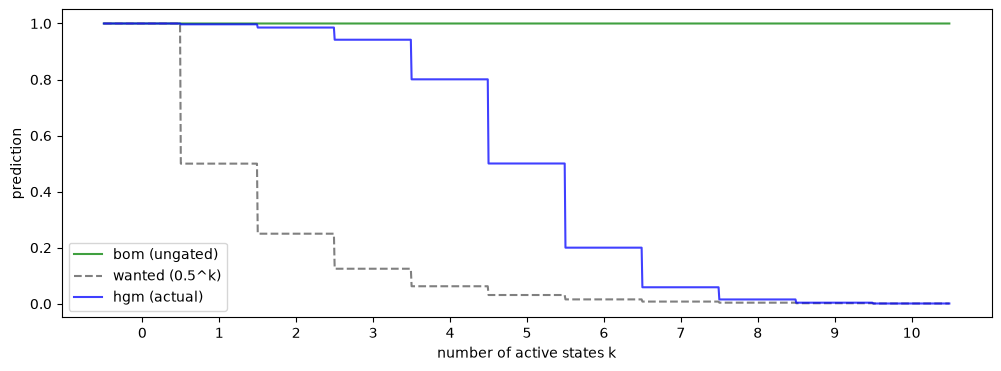

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1. / (1. + np.exp(-x))

d, G, sign = 10, 0.5, -1.
seg = 100                                            # timepoints per segment

# ds: segment k has the first k dimensions at +1, the rest at -1
ds = np.concatenate([np.tile(np.where(np.arange(d) < k, 1., -1.), (seg, 1)) for k in range(d + 1)])  # (n, d)
behavior = np.ones((ds.shape[0], 1))                 # (n, b=1)
bom_w = np.ones((1, 1))                              # (b, m=1)

WZ = np.full((d, 1), sign * -np.log(G))              # (d, m)
gating_min = np.exp(-np.abs(WZ).sum(axis=0))         # (m,)
hgm_w1 = (1. + gating_min) * bom_w                   # (b, m)

bom_ts = behavior @ bom_w                            # (n, m)
hgm_ts = (behavior @ hgm_w1) * sigmoid(ds @ WZ)      # (n, m)
wanted_ts = bom_ts * G ** np.repeat(np.arange(d + 1), seg)[:, None]

t = np.arange(ds.shape[0])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, bom_ts, color='green', alpha=0.75, label='bom (ungated)')
ax.plot(t, wanted_ts, '--', color='gray', label='wanted (0.5^k)')
ax.plot(t, hgm_ts, color='blue', alpha=0.75, label='hgm (actual)')
ax.set_xticks(seg * np.arange(d + 1) + seg / 2, [f'{k}' for k in range(d + 1)])
ax.set_xlabel('number of active states k')
ax.set_ylabel('prediction')
ax.legend()
plt.show()

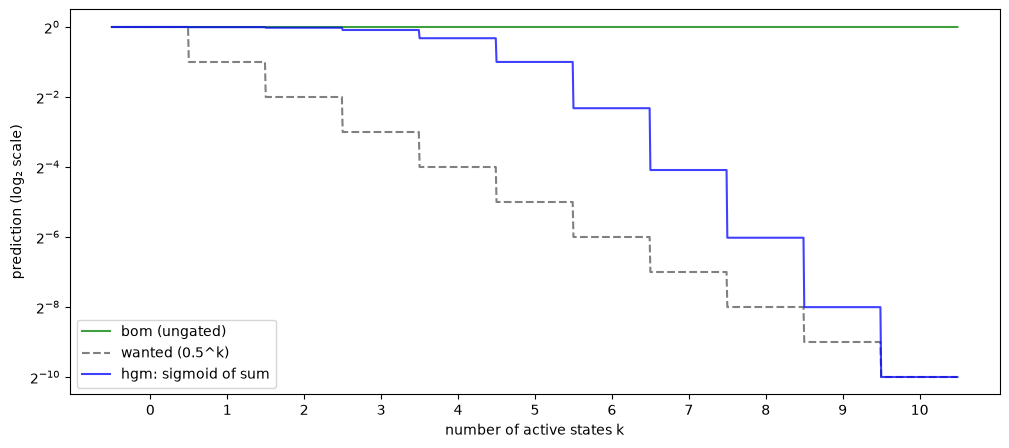

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
      return 1. / (1. + np.exp(-x))

def log_sigmoid(x):
      return -np.logaddexp(0., -x)

d, G, sign = 10, 0.5, -1.
seg = 100                                            # timepoints per segment

# ds: segment k has the first k dimensions at +1, the rest at -1
ds = np.concatenate([np.tile(np.where(np.arange(d) < k, 1., -1.), (seg, 1)) for k in range(d + 1)])  # (n, d)
behavior = np.ones((ds.shape[0], 1))                 # (n, b=1)
bom_w = np.ones((1, 1))                              # (b, m=1)

WZ = np.full((d, 1), sign * -np.log(G))              # (d, m)

# old: one sigmoid over the weighted sum
gating_min = np.exp(-np.abs(WZ).sum(axis=0))                                # (m,)
hgm_w1_sum = (1. + gating_min) * bom_w                                      # (b, m)
hgm_ts_sum = (behavior @ hgm_w1_sum) * sigmoid(ds @ WZ)                     # (n, m)

# new: one sigmoid per dimension, multiplied
hgm_w1_prod = np.prod(1. + np.exp(-np.abs(WZ)), axis=0) * bom_w             # (b, m)
modulation_prod = np.exp(log_sigmoid(ds[:, :, None] * WZ[None, :, :]).sum(axis=1))  # (n, m)
hgm_ts_prod = (behavior @ hgm_w1_prod) * modulation_prod                    # (n, m)

bom_ts = behavior @ bom_w                                                   # (n, m)
wanted_ts = bom_ts * G ** np.repeat(np.arange(d + 1), seg)[:, None]         # (n, m)

t = np.arange(ds.shape[0])
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t, bom_ts, color='green', alpha=0.75, label='bom (ungated)')
ax.plot(t, wanted_ts, '--', color='gray', label='wanted (0.5^k)')
ax.plot(t, hgm_ts_sum, color='blue', alpha=0.75, label='hgm: sigmoid of sum')
# ax.plot(t, hgm_ts_prod, color='red', alpha=0.75, label='hgm: product of sigmoids')
ax.set_yscale('log', base=2)
ax.set_xticks(seg * np.arange(d + 1) + seg / 2, [f'{k}' for k in range(d + 1)])
ax.set_xlabel('number of active states k')
ax.set_ylabel('prediction (log₂ scale)')
ax.legend()
plt.show()